<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [BOE Statistics](https://github.com/Query-farm/vgi-boe)

Discover Bank of England statistical series and retrieve observations with original periods, units and source metadata.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-boe/blob/main/notebooks/02_publication_time_changes_the_comparison.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-boe/blob/main/notebooks/README.md)

## A net-zero revision can hide offsetting changes

Which monthly values were available at a chosen publication cutoff? Do unchanged aggregate totals mean no individual period was revised? First separate catalog additions from series metadata, then use the worker's normalized revision rows to reconstruct an explicitly bounded view.

**This notebook uses an authored synthetic XML scenario.** SYNINDEX and SYNCOUNT are fictional identifiers, values and publication timestamps. The first notebook separately uses unchanged official Bank Rate recordings. No values here describe the Bank of England or actual economic conditions. The real released worker parses the local XML and all historical selection and arithmetic happen in visible SQL.

### Choose a publication cutoff

`AS_OF` is a fictional source-local timestamp: March 15 or April 15, 2024. The observation window stays January–March. March has an observation label before the first cutoff, but its first supplied publication occurs in April. We do not infer a timezone or invent earlier releases absent from the supplied XML.

In [1]:
AS_OF = "2024-03-15 12:00:00"  # Experiment: "2024-04-15 12:00:00"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.32":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.32"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
if AS_OF not in ("2024-03-15 12:00:00", "2024-04-15 12:00:00"):
    raise ValueError("AS_OF must be the March 15 or April 15 synthetic cutoff.")

from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("boe")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from IPython.display import display  # noqa: E402

theme()

from revision_fixture import SyntheticRevisions  # noqa: E402

fixture = SyntheticRevisions()
session = connect(globals())
SOURCE = "Authored XML scenario · fictional series and timestamps · released BOE v0.1.0 parser"

### Connect BOE v0.1.0 to the explicit fixture

The helper selects a strict loopback endpoint and restores prior BOE configuration on cleanup. It serves only the documented synthetic discovery and history requests, makes no outbound requests, and rejects unexpected selectors. The visible launcher uses the public worker release.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'boe' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-boe@v0.1.0 vgi-boe-worker'
);

,Success


### Separate catalog-addition dates from observation history

`new_series()` uses the service's catalog-additions mode for January. Our fixture returns one monthly index and one daily count. Inspect their units and earliest observation labels before choosing a series. The daily series starts in 2020 despite appearing in the synthetic 2024 additions response: catalog inclusion time and earliest observation are different facts. This finite fixture response is not a complete live catalog.

In [5]:
%%sql
CREATE TABLE catalog_additions AS SELECT * FROM boe.main.new_series(
 start_date := '2024-01-01', end_date := '2024-01-31');


,Count


In [6]:
%%sql additions <<
SELECT series_code, title, frequency, unit_descriptor, first_observation, last_observation
FROM catalog_additions
ORDER BY series_code;

In [7]:
display(additions)
assert additions.loc[additions.frequency.eq("M"), "series_code"].tolist() == ["SYNINDEX"]
prose(
    "SYNINDEX is monthly and measured in index points. SYNCOUNT is daily and measured in counts; we keep it outside the numeric comparison. A discovery response alone does not justify aggregating incompatible frequencies or units."
)

,series_code,title,frequency,unit_descriptor,first_observation,last_observation
0,SYNCOUNT,Synthetic daily count,D,Count,2020-01-01,2024-03-01
1,SYNINDEX,Synthetic monthly index,M,Index points,2024-01-01,2024-03-01


SYNINDEX is monthly and measured in index points. SYNCOUNT is daily and measured in counts; we keep it outside the numeric comparison. A discovery response alone does not justify aggregating incompatible frequencies or units.

### Retrieve metadata, current observations and supplied releases

Each call is materialized once. `series()` returns metadata from a bounded XML request; `observations()` retains current and provisional values in separate columns; `revisions()` flattens supplied publication entries and marks current/provisional rows. All three calls use identical series, date and revision controls. The fixture audit later proves their request equality.

The current ordinary value appears once even when its publication is already present among the XML revision entries. A provisional value is a separate candidate, not a second observation to sum or an automatic replacement for the ordinary value.

In [8]:
%%sql
CREATE TABLE metadata AS SELECT * FROM boe.main.series(['SYNINDEX'],
 start_date := '2024-01-01', end_date := '2024-03-31', updated_since := '2024-01-01', include_provisional := true);
CREATE TABLE current_observations AS SELECT * FROM boe.main.observations(['SYNINDEX'],
 start_date := '2024-01-01', end_date := '2024-03-31', updated_since := '2024-01-01', include_provisional := true);
CREATE TABLE releases AS SELECT * FROM boe.main.revisions(['SYNINDEX'],
 start_date := '2024-01-01', end_date := '2024-03-31', updated_since := '2024-01-01', include_provisional := true);

,Count


In [9]:
%%sql released_values <<
SELECT observation_date, published_at, value_text, is_current, is_provisional
FROM releases ORDER BY observation_date, published_at, is_provisional;

In [10]:
display(
    session.connection.execute(
        "SELECT series_code, title, frequency, unit_descriptor, first_observation, last_observation FROM metadata"
    ).df()
)
display(released_values)
prose(
    f"The worker returns **{len(released_values)} publication rows** for three observation periods. One is provisional. The three current ordinary rows match current_observations; earlier publications remain available for the explicit cutoff calculation."
)

,series_code,title,frequency,unit_descriptor,first_observation,last_observation
0,SYNINDEX,Synthetic monthly index,M,Index points,2024-01-01,2024-03-01


,observation_date,published_at,value_text,is_current,is_provisional
0,2024-01-01,2024-02-01 09:30:00,10.00,False,False
1,2024-01-01,2024-04-01 09:30:00,12.00,True,False
2,2024-02-01,2024-03-01 09:30:00,20.00,False,False
3,2024-02-01,2024-04-01 09:30:00,18.00,True,False
4,2024-03-01,2024-04-01 09:30:00,30.00,True,False
5,2024-03-01,2024-04-01 09:30:00,31.00,True,True


The worker returns **6 publication rows** for three observation periods. One is provisional. The three current ordinary rows match current_observations; earlier publications remain available for the explicit cutoff calculation.

### Select the latest eligible publication for each observation period

Filter out provisional releases and publications after the cutoff, then rank by parsed publication timestamp **within each period**. Left join from all three current observation periods so a period with no eligible publication remains visible as missing. Parse the original numeric text as DECIMAL for exact comparison.

In [11]:
%%sql comparison <<
WITH eligible AS (
 SELECT *, row_number() OVER (PARTITION BY series_code, observation_date ORDER BY cast(published_at AS TIMESTAMP) DESC) AS rn
 FROM releases WHERE NOT is_provisional AND cast(published_at AS TIMESTAMP) <= TIMESTAMP '{{AS_OF}}'
)
SELECT o.series_code, o.observation_date, cast(o.value_text AS DECIMAL(12,2)) AS current_value,
       e.published_at AS selected_publication, cast(e.value_text AS DECIMAL(12,2)) AS as_of_value,
       cast(o.value_text AS DECIMAL(12,2))-cast(e.value_text AS DECIMAL(12,2)) AS revision_points
FROM current_observations o LEFT JOIN eligible e
 ON o.series_code=e.series_code AND o.observation_date=e.observation_date AND e.rn=1
ORDER BY o.observation_date;

,series_code,observation_date,current_value,selected_publication,as_of_value,revision_points
0,SYNINDEX,2024-01-01,12.0,2024-02-01 09:30:00,10.0,2.0
1,SYNINDEX,2024-02-01,18.0,2024-03-01 09:30:00,20.0,-2.0
2,SYNINDEX,2024-03-01,30.0,None,NaN,NaN


At **2024-03-15 12:00:00**, **2 of 3 periods** have a supplied eligible ordinary release. Their matched net revision is **+0.00 index points**, while absolute revisions total **4.00**. The net-zero comparison hides offsetting period-level revisions. The missing period is excluded from both sides of the matched comparison.

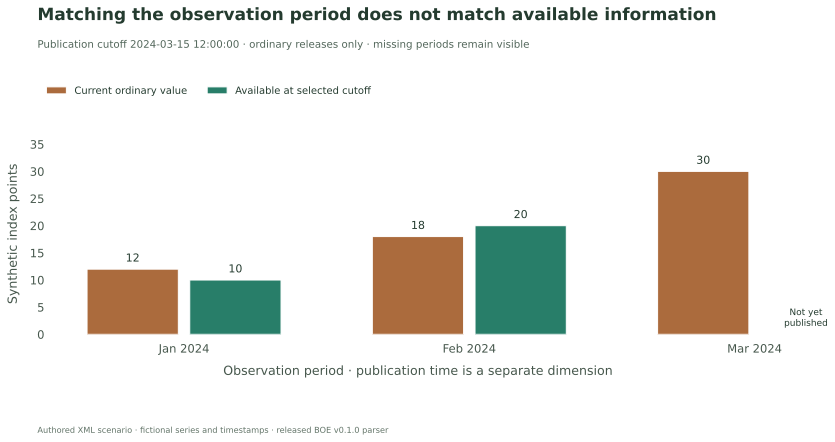

In [12]:
display(comparison)
known = comparison.as_of_value.notna()
net = comparison.loc[known, "revision_points"].sum()
gross = comparison.loc[known, "revision_points"].abs().sum()
prose(
    f"At **{AS_OF}**, **{int(known.sum())} of {len(comparison)} periods** have a supplied eligible ordinary release. Their matched net revision is **{net:+.2f} index points**, while absolute revisions total **{gross:.2f}**. {'The net-zero comparison hides offsetting period-level revisions.' if gross else 'Every available ordinary value now matches the current observation.'} {'The missing period is excluded from both sides of the matched comparison.' if not known.all() else 'All three periods have eligible publications at this cutoff.'}"
)
fig, ax = plt.subplots(figsize=(11.5, 6.5))
x = np.arange(len(comparison))
bars = ax.bar(x - 0.18, comparison.current_value, width=0.32, color="#AB6B3D", label="Current ordinary value")
ax.bar_label(bars, padding=5)
bars = ax.bar(
    x[known] + 0.18,
    comparison.loc[known, "as_of_value"],
    width=0.32,
    color="#287E69",
    label="Available at selected cutoff",
)
ax.bar_label(bars, padding=5)
for i in x[~known]:
    ax.text(i + 0.18, 1, "Not yet\npublished", ha="center", va="bottom", fontsize=9)
ax.set(
    xticks=x,
    xticklabels=pd.to_datetime(comparison.observation_date).dt.strftime("%b %Y"),
    ylabel="Synthetic index points",
    xlabel="Observation period · publication time is a separate dimension",
    ylim=(0, 37),
)
fig.legend(*ax.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.07, 0.82), ncol=2, fontsize=10)
finish(
    fig,
    "Matching the observation period does not match available information",
    f"Publication cutoff {AS_OF} · ordinary releases only · missing periods remain visible",
    SOURCE,
    name="publication-cutoff-" + AS_OF[:10],
)

### Check identities, availability and provisional separation

The checks reconcile current ordinary revision rows with current observations, preserve the provisional value separately, and require exactly one eligible selection per known period. They also reject duplicate publication keys or unparseable timestamp/numeric text. These are controlled parser/query checks; they do not prove that a live response contains every historical release.

In [13]:
%%sql checks <<
SELECT 'one monthly metadata record' AS check_name, (SELECT count(*)=1 AND bool_and(frequency='M' AND unit_descriptor='Index points') FROM metadata) AS passed
UNION ALL SELECT 'three unique observation periods', (SELECT count(*)=3 AND count(DISTINCT observation_date)=3 FROM current_observations)
UNION ALL SELECT 'six unique supplied publication keys', (SELECT count(*)=6 AND count(DISTINCT (observation_date,published_at,is_provisional))=6 FROM releases)
UNION ALL SELECT 'publication strings parse without inferred timezone', (SELECT bool_and(try_cast(published_at AS TIMESTAMP) IS NOT NULL) FROM releases)
UNION ALL SELECT 'numeric text preserves exact source value', (SELECT bool_and(cast(value_text AS DECIMAL(12,2))::DOUBLE=value) FROM releases)
UNION ALL SELECT 'three current ordinary rows reconcile', (SELECT count(*)=3 AND bool_and(r.value_text=o.value_text) FROM releases r JOIN current_observations o USING(series_code,observation_date) WHERE r.is_current AND NOT r.is_provisional)
UNION ALL SELECT 'provisional remains separate', (SELECT count(*)=1 AND bool_and(r.value_text=o.provisional_value_text) FROM releases r JOIN current_observations o USING(series_code,observation_date) WHERE r.is_provisional)
UNION ALL SELECT 'earlier revisions retained', (SELECT count(*)=2 FROM releases WHERE NOT is_current AND NOT is_provisional)
UNION ALL SELECT 'eligible source publications carry numeric text', (SELECT count(*)=0 FROM releases WHERE NOT is_provisional AND cast(published_at AS TIMESTAMP)<=TIMESTAMP '{{AS_OF}}' AND value_text IS NULL)
ORDER BY check_name;

In [14]:
display(checks)
assert len(checks) == 9 and checks.passed.notna().all() and checks.passed.all()
assert (
    comparison.loc[comparison.as_of_value.notna(), "selected_publication"]
    .map(pd.Timestamp)
    .le(pd.Timestamp(AS_OF))
    .all()
)
assert len(fixture.requests) == 4 and fixture.requests[0]["route"] == "catalog-additions"
assert all(r["query"] == fixture.requests[1]["query"] for r in fixture.requests[1:])
assert len({r["response_bytes"] for r in fixture.requests[1:]}) == 1
display(pd.DataFrame(fixture.requests))
prose(
    "All checks pass. Three identical bounded XML requests serve metadata, current observations and flattened revisions. The catalog-additions request uses its distinct selector mode. No local query fills a missing release or mixes the provisional row into an ordinary-value total."
)

,check_name,passed
0,earlier revisions retained,True
1,eligible source publications carry numeric text,True
2,numeric text preserves exact source value,True
3,one monthly metadata record,True
4,provisional remains separate,True
5,publication strings parse without inferred tim...,True
6,six unique supplied publication keys,True
7,three current ordinary rows reconcile,True
8,three unique observation periods,True


,route,query,response_bytes
0,catalog-additions,"{'CodeVer': ['new'], 'xml.x': ['yes'], 'Datefr...",812
1,publication-history,"{'CodeVer': ['new'], 'xml.x': ['yes'], 'Datefr...",1119
2,publication-history,"{'CodeVer': ['new'], 'xml.x': ['yes'], 'Datefr...",1119
3,publication-history,"{'CodeVer': ['new'], 'xml.x': ['yes'], 'Datefr...",1119


All checks pass. Three identical bounded XML requests serve metadata, current observations and flattened revisions. The catalog-additions request uses its distinct selector mode. No local query fills a missing release or mixes the provisional row into an ordinary-value total.

### Experiment: move only the publication cutoff

Change **`AS_OF` to `"2024-04-15 12:00:00"`**, restart and run all. Predict that March becomes available and the earlier two periods match current values. Check the count of known periods, net and absolute revisions, and the chart. The six publication rows, three current observations, metadata and four request selectors must stay fixed.

This is a complete authored scenario, not a claim that the live service is a complete vintage archive. Only supplied releases can be selected. Catalog addition dates, observation periods, source publication strings and the time you acquire the response must remain distinct.

In [15]:
session.close()
fixture.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-boe](https://github.com/Query-farm/vgi-boe)